In [76]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

In [77]:
# NO instalar torch, tensorflow ni cuda-bindings.
# Kaggle ya los trae instalados.

!pip install -q timm --no-deps
!pip install -q imbalanced-learn scikit-image openpyxl xlrd opencv-python-headless --no-deps

In [78]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import glob
import random
import shutil
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image
from skimage.color import rgb2lab, rgb2hsv
from skimage.segmentation import slic

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import Ridge

from imblearn.over_sampling import SMOTE
from imblearn.ensemble import RUSBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

# GPU config para Kaggle
gpus_tf = tf.config.list_physical_devices("GPU")
for gpu in gpus_tf:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception:
        pass

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

print("PyTorch CUDA disponible:", torch.cuda.is_available())
print("Número de GPUs PyTorch:", torch.cuda.device_count())
print("TensorFlow GPUs:", gpus_tf)
print("Device PyTorch:", device)
if torch.cuda.is_available():
    print("GPU principal:", torch.cuda.get_device_name(0))

PyTorch CUDA disponible: True
Número de GPUs PyTorch: 2
TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Device PyTorch: cuda
GPU principal: Tesla T4


In [ ]:
# Kaggle: no usar Google Drive.
# Los datasets ya están agregados como Input y se leen desde /kaggle/input.
# Los resultados se guardan en /kaggle/working.

In [79]:
CP_SOURCE = "/kaggle/input/datasets/sharksoft/cpanemic/CPANEMIC/CP-AnemiC dataset"
EYES_SOURCE = "/kaggle/input/datasets/sharksoft/eyesdefyanemia/EYESDEFYANEMIA/archive/dataset anemia"

OUTPUT_DIR = "/kaggle/working/resultados_modelos_solo_matriz"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("CP_SOURCE existe:", os.path.exists(CP_SOURCE))
print("EYES_SOURCE existe:", os.path.exists(EYES_SOURCE))
print("OUTPUT_DIR existe:", os.path.exists(OUTPUT_DIR))

print("\nContenido CP_SOURCE:")
print(os.listdir(CP_SOURCE))

print("\nContenido EYES_SOURCE:")
print(os.listdir(EYES_SOURCE))

CP_SOURCE existe: True
EYES_SOURCE existe: True
OUTPUT_DIR existe: True

Contenido CP_SOURCE:
['Non-anemic', 'Anemic', 'Anemia_Data_Collection_Sheet.xlsx']

Contenido EYES_SOURCE:
['Italy', 'Dataset anemia.docx', 'India']


In [80]:
def gray_world_white_balance(img_rgb):
    img = img_rgb.astype(np.float32)

    avg_r = np.mean(img[:, :, 0])
    avg_g = np.mean(img[:, :, 1])
    avg_b = np.mean(img[:, :, 2])
    avg_gray = (avg_r + avg_g + avg_b) / 3

    img[:, :, 0] *= avg_gray / (avg_r + 1e-6)
    img[:, :, 1] *= avg_gray / (avg_g + 1e-6)
    img[:, :, 2] *= avg_gray / (avg_b + 1e-6)

    img = np.clip(img, 0, 255)
    return img.astype(np.uint8)


def clahe_lab_correction(img_rgb):
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l2 = clahe.apply(l)

    lab2 = cv2.merge((l2, a, b))
    corrected = cv2.cvtColor(lab2, cv2.COLOR_LAB2RGB)

    return corrected


def load_preprocessed_image(image_path, img_size=(224, 224)):
    img = Image.open(image_path).convert("RGB").resize(img_size)
    arr = np.array(img).astype(np.uint8)

    arr = gray_world_white_balance(arr)
    arr = clahe_lab_correction(arr)

    return arr

In [81]:
def extract_color_features(image_path, img_size=(224, 224), use_slic=False):
    img_rgb = load_preprocessed_image(image_path, img_size)
    arr = img_rgb.astype(np.float32) / 255.0

    lab = rgb2lab(arr)
    hsv = rgb2hsv(arr)

    features = []

    for space in [arr, lab, hsv]:
        for c in range(3):
            ch = space[:, :, c]
            features.extend([
                np.mean(ch),
                np.std(ch),
                np.median(ch),
                np.percentile(ch, 5),
                np.percentile(ch, 10),
                np.percentile(ch, 25),
                np.percentile(ch, 75),
                np.percentile(ch, 90),
                np.percentile(ch, 95),
                np.min(ch),
                np.max(ch)
            ])

    R = arr[:, :, 0]
    G = arr[:, :, 1]
    B = arr[:, :, 2]
    eps = 1e-6

    features.extend([
        np.mean(R / (G + eps)),
        np.mean(R / (B + eps)),
        np.mean(G / (B + eps)),
        np.mean(R - G),
        np.mean(R - B),
        np.mean(G - B),
        np.std(R - G),
        np.std(R - B),
        np.std(G - B)
    ])

    L = lab[:, :, 0]
    a = lab[:, :, 1]
    b = lab[:, :, 2]

    features.extend([
        np.mean(L), np.std(L),
        np.mean(a), np.std(a),
        np.mean(b), np.std(b),
        np.mean(a / (L + eps)),
        np.mean(b / (L + eps)),
        np.mean((a + b) / (L + eps))
    ])

    if use_slic:
        segments = slic(arr, n_segments=80, compactness=10, start_label=1)

        for c in range(3):
            ch = lab[:, :, c]
            seg_means = []

            for seg_id in np.unique(segments):
                values = ch[segments == seg_id]
                seg_means.append(np.mean(values))

            seg_means = np.array(seg_means)

            features.extend([
                np.mean(seg_means),
                np.std(seg_means),
                np.percentile(seg_means, 10),
                np.percentile(seg_means, 25),
                np.percentile(seg_means, 50),
                np.percentile(seg_means, 75),
                np.percentile(seg_means, 90)
            ])

    return np.array(features, dtype=np.float32)

In [82]:
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".JPG", ".JPEG", ".PNG", ".BMP")

classes = ["Anemic", "Non-anemic"]
ANEMIC_INDEX = 0

def get_images(folder):
    files = []
    for ext in IMG_EXTS:
        files.extend(glob.glob(os.path.join(folder, f"*{ext}")))
    return files

all_files = []
all_labels = []

for cls in classes:
    folder = os.path.join(CP_SOURCE, cls)
    images = get_images(folder)
    print(cls, len(images))

    for img in images:
        all_files.append(img)
        all_labels.append(cls)

print("Total imágenes:", len(all_files))
print(pd.Series(all_labels).value_counts())

Anemic 424
Non-anemic 286
Total imágenes: 710
Anemic        424
Non-anemic    286
Name: count, dtype: int64


In [83]:
train_files, temp_files, train_labels, temp_labels = train_test_split(
    all_files,
    all_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=all_labels
)

val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

def labels_to_numeric(labels):
    return np.array([classes.index(x) for x in labels])

y_train = labels_to_numeric(train_labels)
y_val = labels_to_numeric(val_labels)
y_test = labels_to_numeric(test_labels)

print("Train:", len(train_files), np.bincount(y_train))
print("Val:", len(val_files), np.bincount(y_val))
print("Test:", len(test_files), np.bincount(y_test))

Train: 497 [297 200]
Val: 106 [63 43]
Test: 107 [64 43]


In [84]:
def find_best_threshold(y_true, y_score, positive_label=0):
    thresholds = np.arange(0.05, 0.96, 0.01)

    best_thr = 0.5
    best_score = -1

    for thr in thresholds:
        y_pred = np.where(y_score >= thr, positive_label, 1 - positive_label)

        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, pos_label=positive_label, zero_division=0)
        sens = recall_score(y_true, y_pred, pos_label=positive_label, zero_division=0)
        f1 = f1_score(y_true, y_pred, pos_label=positive_label, zero_division=0)

        cm = confusion_matrix(y_true, y_pred, labels=[positive_label, 1-positive_label])
        TP, FN = cm[0, 0], cm[0, 1]
        FP, TN = cm[1, 0], cm[1, 1]
        spec = TN / (TN + FP) if (TN + FP) > 0 else 0

        score = 0.30 * sens + 0.25 * f1 + 0.20 * prec + 0.15 * acc + 0.10 * spec

        if score > best_score:
            best_score = score
            best_thr = thr

    return best_thr


def evaluate_classifier(model_name, y_true, y_score, threshold=0.5, positive_index=0):
    y_pred = np.where(y_score >= threshold, positive_index, 1 - positive_index)

    neg_index = 1 - positive_index
    cm = confusion_matrix(y_true, y_pred, labels=[positive_index, neg_index])

    TP = cm[0, 0]
    FN = cm[0, 1]
    FP = cm[1, 0]
    TN = cm[1, 1]

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, pos_label=positive_index, zero_division=0)
    sensitivity = recall_score(y_true, y_pred, pos_label=positive_index, zero_division=0)
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    f1 = f1_score(y_true, y_pred, pos_label=positive_index, zero_division=0)

    y_binary = (y_true == positive_index).astype(int)
    auc = roc_auc_score(y_binary, y_score)

    print(f"\n===== {model_name} =====")
    print("Threshold:", round(threshold, 3))
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Sensibilidad:", round(sensitivity, 4))
    print("Especificidad:", round(specificity, 4))
    print("F1-score:", round(f1, 4))
    print("AUC:", round(auc, 4))
    print("TP:", TP, "FN:", FN, "FP:", FP, "TN:", TN)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Anemic", "Non-anemic"]
    )
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusión - {model_name}")
    plt.tight_layout()

    matrix_path = os.path.join(OUTPUT_DIR, f"matriz_confusion_{model_name}.png")
    plt.savefig(matrix_path, dpi=300, bbox_inches="tight")
    plt.show()

    return {
        "Modelo": model_name,
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensibilidad": sensitivity,
        "Especificidad": specificity,
        "F1-score": f1,
        "AUC": auc,
        "TP": TP,
        "FN": FN,
        "FP": FP,
        "TN": TN
    }

In [85]:
def build_feature_matrix(files, use_slic=False):
    X = []

    for i, path in enumerate(files):
        if i % 100 == 0:
            print("Procesando imagen", i, "de", len(files))
        X.append(extract_color_features(path, use_slic=use_slic))

    return np.array(X)

X_train_feat = build_feature_matrix(train_files, use_slic=False)
X_val_feat = build_feature_matrix(val_files, use_slic=False)
X_test_feat = build_feature_matrix(test_files, use_slic=False)

print("X_train_feat:", X_train_feat.shape)
print("X_val_feat:", X_val_feat.shape)
print("X_test_feat:", X_test_feat.shape)

Procesando imagen 0 de 497
Procesando imagen 100 de 497
Procesando imagen 200 de 497
Procesando imagen 300 de 497
Procesando imagen 400 de 497
Procesando imagen 0 de 106
Procesando imagen 100 de 106
Procesando imagen 0 de 107
Procesando imagen 100 de 107
X_train_feat: (497, 117)
X_val_feat: (106, 117)
X_test_feat: (107, 117)


Mejores parámetros kNN + SMOTE: {'clf__metric': 'manhattan', 'clf__n_neighbors': 7, 'clf__weights': 'distance'}

===== kNN_SMOTE_ROSE =====
Threshold: 0.4
Accuracy: 0.8131
Precision: 0.8143
Sensibilidad: 0.8906
Especificidad: 0.6977
F1-score: 0.8507
AUC: 0.9182
TP: 57 FN: 7 FP: 13 TN: 30


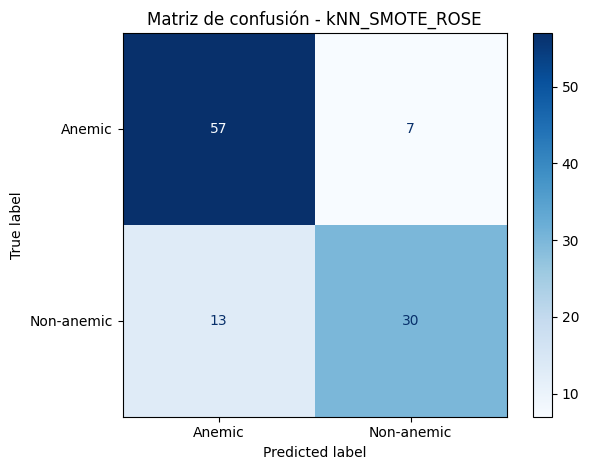

In [86]:
classification_results = []

knn_smote = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=SEED)),
    ("clf", KNeighborsClassifier())
])

knn_params = {
    "clf__n_neighbors": [1, 3, 5, 7, 9],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "manhattan"]
}

knn_grid = GridSearchCV(
    knn_smote,
    knn_params,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

knn_grid.fit(X_train_feat, y_train)

print("Mejores parámetros kNN + SMOTE:", knn_grid.best_params_)

knn_best = knn_grid.best_estimator_

y_val_score = knn_best.predict_proba(X_val_feat)[:, ANEMIC_INDEX]
y_test_score = knn_best.predict_proba(X_test_feat)[:, ANEMIC_INDEX]

best_thr = find_best_threshold(y_val, y_val_score, positive_label=ANEMIC_INDEX)

res = evaluate_classifier(
    "kNN_SMOTE_ROSE",
    y_test,
    y_test_score,
    threshold=best_thr,
    positive_index=ANEMIC_INDEX
)

classification_results.append(res)

Mejores parámetros RUSBoost: {'learning_rate': 1.0, 'n_estimators': 100}

===== RUSBoost =====
Threshold: 0.05
Accuracy: 0.5981
Precision: 0.5981
Sensibilidad: 1.0
Especificidad: 0.0
F1-score: 0.7485
AUC: 0.5823
TP: 64 FN: 0 FP: 43 TN: 0


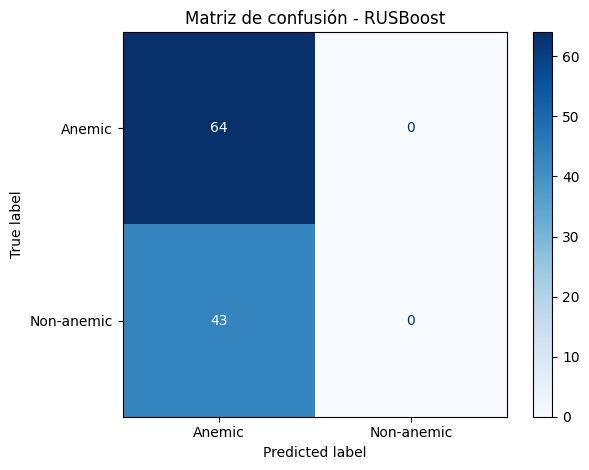

In [87]:
rusboost = RUSBoostClassifier(random_state=SEED)

rus_params = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0]
}

rus_grid = GridSearchCV(
    rusboost,
    rus_params,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

rus_grid.fit(X_train_feat, y_train)

print("Mejores parámetros RUSBoost:", rus_grid.best_params_)

rus_best = rus_grid.best_estimator_

y_val_score = rus_best.predict_proba(X_val_feat)[:, ANEMIC_INDEX]
y_test_score = rus_best.predict_proba(X_test_feat)[:, ANEMIC_INDEX]

best_thr = find_best_threshold(y_val, y_val_score, positive_label=ANEMIC_INDEX)

res = evaluate_classifier(
    "RUSBoost",
    y_test,
    y_test_score,
    threshold=best_thr,
    positive_index=ANEMIC_INDEX
)

classification_results.append(res)

In [88]:
CP_TF_DIR = "/kaggle/working/cp_tf_matrix"

if os.path.exists(CP_TF_DIR):
    shutil.rmtree(CP_TF_DIR)

for split in ["train", "val", "test"]:
    for cls in classes:
        os.makedirs(os.path.join(CP_TF_DIR, split, cls), exist_ok=True)

def copy_to_tf_structure(files, labels, split):
    for i, (path, label) in enumerate(zip(files, labels)):
        dest = os.path.join(CP_TF_DIR, split, label, f"{i}_{os.path.basename(path)}")
        shutil.copy(path, dest)

copy_to_tf_structure(train_files, train_labels, "train")
copy_to_tf_structure(val_files, val_labels, "val")
copy_to_tf_structure(test_files, test_labels, "test")

In [89]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CP_TF_DIR, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CP_TF_DIR, "val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CP_TF_DIR, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Guardar nombres de clases ANTES del prefetch
class_names_tf = train_ds.class_names
print("Clases:", class_names_tf)

# Verificar índice de Anemic
ANEMIC_INDEX = class_names_tf.index("Anemic")
print("Índice de Anemic:", ANEMIC_INDEX)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 497 files belonging to 2 classes.
Found 106 files belonging to 2 classes.
Found 107 files belonging to 2 classes.
Clases: ['Anemic', 'Non-anemic']
Índice de Anemic: 0


In [90]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
])

def build_cnn_model():
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1./255)(x)

    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(256, 3, activation="relu", padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.45)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(2, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    return model

y_train_for_weights = []

for _, labels in train_ds.unbatch():
    y_train_for_weights.append(int(labels.numpy()))

class_counts = np.bincount(y_train_for_weights)
class_weights = {
    0: len(y_train_for_weights) / (2 * class_counts[0]),
    1: len(y_train_for_weights) / (2 * class_counts[1])
}

print("Class weights:", class_weights)

Class weights: {0: np.float64(0.8367003367003367), 1: np.float64(1.2425)}


Epoch 1/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step - accuracy: 0.4950 - loss: 0.7086 - val_accuracy: 0.5943 - val_loss: 0.6872 - learning_rate: 1.0000e-04
Epoch 2/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 144ms/step - accuracy: 0.5131 - loss: 0.7030 - val_accuracy: 0.5943 - val_loss: 0.6868 - learning_rate: 1.0000e-04
Epoch 3/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.4909 - loss: 0.6855 - val_accuracy: 0.5943 - val_loss: 0.6848 - learning_rate: 1.0000e-04
Epoch 4/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step - accuracy: 0.5211 - loss: 0.6809 - val_accuracy: 0.5943 - val_loss: 0.6875 - learning_rate: 1.0000e-04
Epoch 5/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.5594 - loss: 0.6845 - val_accuracy: 0.4057 - val_loss: 0.7065 - learning_rate: 1.0000e-04
Epoch 6/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.5915 - loss: 0.6647 - val_accuracy: 0.4057 - val_loss: 0.7167 - learning_rate: 1.0000e-04
Epoch 7/40
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 143ms/step - accuracy: 

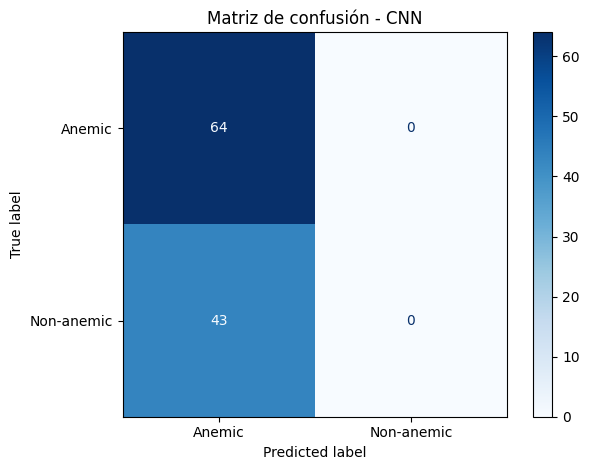

In [91]:
cnn_model = build_cnn_model()

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    class_weight=class_weights,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=4),
        ModelCheckpoint(os.path.join(OUTPUT_DIR, "CNN_model.keras"), save_best_only=True)
    ]
)

def get_true_labels_tf(dataset):
    labels = []
    for _, y in dataset:
        labels.extend(y.numpy())
    return np.array(labels)

y_val_tf = get_true_labels_tf(val_ds)
y_test_tf = get_true_labels_tf(test_ds)

y_val_score = cnn_model.predict(val_ds)[:, ANEMIC_INDEX]
y_test_score = cnn_model.predict(test_ds)[:, ANEMIC_INDEX]

best_thr = find_best_threshold(y_val_tf, y_val_score, positive_label=ANEMIC_INDEX)

res = evaluate_classifier(
    "CNN",
    y_test_tf,
    y_test_score,
    threshold=best_thr,
    positive_index=ANEMIC_INDEX
)

classification_results.append(res)

In [92]:
def image_paths_to_mobilenet_embeddings(files, batch_size=32):
    base = MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=(224, 224, 3),
        pooling="avg"
    )
    base.trainable = False

    X = []

    for i in range(0, len(files), batch_size):
        batch_files = files[i:i+batch_size]
        imgs = []

        for path in batch_files:
            img = load_preprocessed_image(path, IMG_SIZE)
            imgs.append(img.astype(np.float32))

        imgs = np.array(imgs)
        imgs = mobilenet_preprocess(imgs)

        emb = base(imgs, training=False).numpy()
        X.append(emb)

    return np.vstack(X)

X_train_emb = image_paths_to_mobilenet_embeddings(train_files)
X_val_emb = image_paths_to_mobilenet_embeddings(val_files)
X_test_emb = image_paths_to_mobilenet_embeddings(test_files)

print("Embeddings train:", X_train_emb.shape)

Embeddings train: (497, 1280)


Mejores parámetros MobileNetV2 + SVM: {'clf__C': 10, 'clf__gamma': 0.001, 'clf__kernel': 'rbf'}

===== MobileNetV2_SVM =====
Threshold: 0.43
Accuracy: 0.7383
Precision: 0.7571
Sensibilidad: 0.8281
Especificidad: 0.6047
F1-score: 0.791
AUC: 0.8692
TP: 53 FN: 11 FP: 17 TN: 26


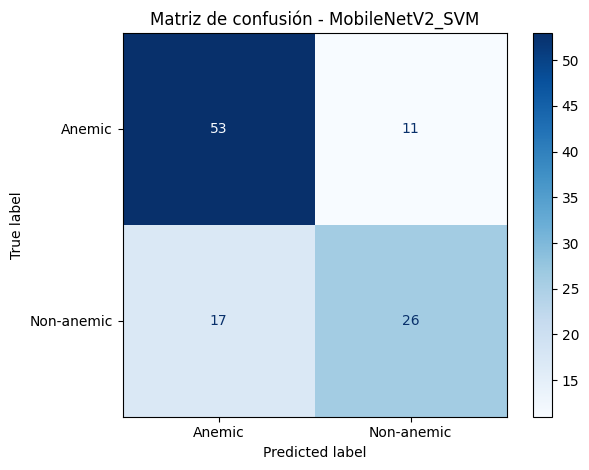

In [93]:
mobilenet_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(probability=True, class_weight="balanced", random_state=SEED))
])

mobilenet_svm_params = {
    "clf__C": [0.1, 1, 10, 50, 100],
    "clf__gamma": ["scale", 0.01, 0.001],
    "clf__kernel": ["rbf", "linear"]
}

mobilenet_svm_grid = GridSearchCV(
    mobilenet_svm,
    mobilenet_svm_params,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1
)

mobilenet_svm_grid.fit(X_train_emb, y_train)

print("Mejores parámetros MobileNetV2 + SVM:", mobilenet_svm_grid.best_params_)

mobilenet_svm_best = mobilenet_svm_grid.best_estimator_

y_val_score = mobilenet_svm_best.predict_proba(X_val_emb)[:, ANEMIC_INDEX]
y_test_score = mobilenet_svm_best.predict_proba(X_test_emb)[:, ANEMIC_INDEX]

best_thr = find_best_threshold(y_val, y_val_score, positive_label=ANEMIC_INDEX)

res = evaluate_classifier(
    "MobileNetV2_SVM",
    y_test,
    y_test_score,
    threshold=best_thr,
    positive_index=ANEMIC_INDEX
)

classification_results.append(res)

In [95]:
class ImageClassificationDataset(Dataset):
    def __init__(self, files, labels, img_size=224):
        self.files = files
        self.labels = labels
        self.img_size = img_size
        self.label_map = {"Anemic": 0, "Non-anemic": 1}
        self.mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
        self.std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = load_preprocessed_image(self.files[idx], (self.img_size, self.img_size))
        arr = img.astype(np.float32) / 255.0
        arr = np.transpose(arr, (2, 0, 1))
        arr = (arr - self.mean) / self.std

        label = self.label_map[self.labels[idx]]
        return torch.tensor(arr, dtype=torch.float32), torch.tensor(label, dtype=torch.long)

train_dataset_torch = ImageClassificationDataset(train_files, train_labels)
val_dataset_torch = ImageClassificationDataset(val_files, val_labels)
test_dataset_torch = ImageClassificationDataset(test_files, test_labels)

train_loader = DataLoader(train_dataset_torch, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset_torch, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset_torch, batch_size=16, shuffle=False)

In [96]:
def train_deit_classifier(model_name="deit_small_patch16_224", epochs=25, lr=1e-4):
    model = timm.create_model(model_name, pretrained=True, num_classes=2)
    model = model.to(device)

    class_counts = np.bincount(y_train)
    weights = torch.tensor(
        len(y_train) / (2 * class_counts),
        dtype=torch.float32
    ).to(device)

    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    best_val_loss = np.inf
    best_state = None
    patience = 6
    wait = 0

    for epoch in range(epochs):
        model.train()
        train_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        model.eval()
        val_loss = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = model.state_dict()
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    return model


def predict_deit_classifier(model, loader):
    model.eval()
    y_true = []
    y_score = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1).cpu().numpy()

            y_true.extend(labels.numpy())
            y_score.extend(probs[:, ANEMIC_INDEX])

    return np.array(y_true), np.array(y_score)

Epoch 1/25 | Train Loss: 21.9863 | Val Loss: 4.2610
Epoch 2/25 | Train Loss: 19.5645 | Val Loss: 3.8368
Epoch 3/25 | Train Loss: 12.9700 | Val Loss: 4.6268
Epoch 4/25 | Train Loss: 8.5015 | Val Loss: 3.8533
Epoch 5/25 | Train Loss: 6.2611 | Val Loss: 3.1027
Epoch 6/25 | Train Loss: 2.6511 | Val Loss: 4.3087
Epoch 7/25 | Train Loss: 2.3186 | Val Loss: 7.6652
Epoch 8/25 | Train Loss: 5.5867 | Val Loss: 5.1268
Epoch 9/25 | Train Loss: 1.6172 | Val Loss: 5.9321
Epoch 10/25 | Train Loss: 3.2585 | Val Loss: 7.1211
Epoch 11/25 | Train Loss: 0.9076 | Val Loss: 6.0813
Early stopping

===== DeiT_ViT =====
Threshold: 0.17
Accuracy: 0.729
Precision: 0.7536
Sensibilidad: 0.8125
Especificidad: 0.6047
F1-score: 0.782
AUC: 0.8656
TP: 52 FN: 12 FP: 17 TN: 26


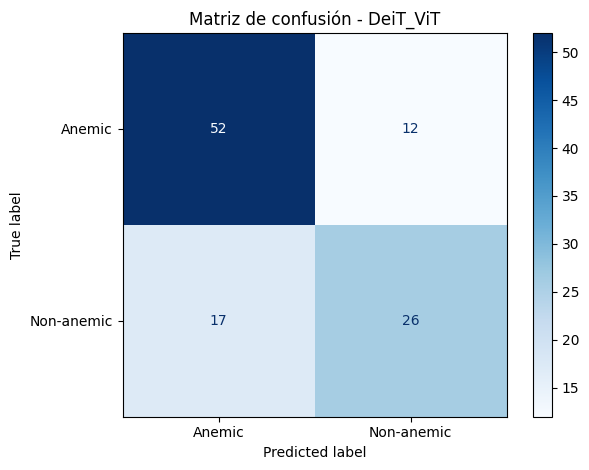

In [97]:
deit_model = train_deit_classifier(
    model_name="deit_small_patch16_224",
    epochs=25,
    lr=1e-4
)

y_val_deit, y_val_score = predict_deit_classifier(deit_model, val_loader)
y_test_deit, y_test_score = predict_deit_classifier(deit_model, test_loader)

best_thr = find_best_threshold(y_val_deit, y_val_score, positive_label=ANEMIC_INDEX)

res = evaluate_classifier(
    "DeiT_ViT",
    y_test_deit,
    y_test_score,
    threshold=best_thr,
    positive_index=ANEMIC_INDEX
)

classification_results.append(res)

In [98]:
def find_column(df, possible_names):
    cols = list(df.columns)
    clean_cols = {str(c).strip().lower(): c for c in cols}

    for name in possible_names:
        name = name.lower()
        for clean, original in clean_cols.items():
            if name in clean:
                return original

    return None


def to_float_safe(x):
    if pd.isna(x):
        return np.nan

    try:
        return float(str(x).replace(",", "."))
    except:
        return np.nan


def choose_palpebral_image(folder):
    """
    Selecciona preferentemente imagen de conjuntiva palpebral.
    Considera errores de escritura presentes en el dataset: papebral / palplebral.
    Prioridad:
    1) archivo .png con palpebral/papebral/palplebral sin 'forniceal'
    2) archivo .png con forniceal_palpebral
    3) cualquier imagen .jpg/.png disponible
    """
    if not os.path.exists(folder):
        return None

    all_imgs = []
    for ext in IMG_EXTS:
        all_imgs.extend(glob.glob(os.path.join(folder, f"*{ext}")))

    if len(all_imgs) == 0:
        return None

    def is_palpebral(p):
        name = os.path.basename(p).lower()
        return ("palpebral" in name) or ("papebral" in name) or ("palplebral" in name)

    pure_palpebral = [
        p for p in all_imgs
        if is_palpebral(p) and ("forniceal" not in os.path.basename(p).lower())
    ]

    if len(pure_palpebral) > 0:
        pure_palpebral = sorted(
            pure_palpebral,
            key=lambda p: (not p.lower().endswith(".png"), len(os.path.basename(p)))
        )
        return pure_palpebral[0]

    mixed = [p for p in all_imgs if is_palpebral(p)]

    if len(mixed) > 0:
        mixed = sorted(
            mixed,
            key=lambda p: (not p.lower().endswith(".png"), len(os.path.basename(p)))
        )
        return mixed[0]

    fallback = sorted(
        all_imgs,
        key=lambda p: (not p.lower().endswith(".jpg"), len(os.path.basename(p)))
    )
    return fallback[0]


def load_eyes_defy_dataset(base_path):
    rows = []

    for country in ["Italy", "India"]:
        country_path = os.path.join(base_path, country)

        excel_files = glob.glob(os.path.join(country_path, "*.xls*"))

        if len(excel_files) == 0:
            print("No se encontró Excel en:", country_path)
            continue

        excel_path = excel_files[0]
        df = pd.read_excel(excel_path)

        print("\nColumnas en", country, ":", list(df.columns))

        number_col = find_column(df, ["number", "numero", "n"])
        hb_col = find_column(df, ["hgb", "hb", "hemoglobin", "haemoglobin"])
        sex_col = find_column(df, ["sex", "gender", "sexo"])
        age_col = find_column(df, ["age", "edad"])

        if number_col is None or hb_col is None:
            raise ValueError(f"No pude detectar Number o Hb en {excel_path}")

        for _, row in df.iterrows():
            number = row[number_col]
            hb = to_float_safe(row[hb_col])

            if pd.isna(number) or pd.isna(hb):
                continue

            folder = os.path.join(country_path, str(int(number)))
            img_path = choose_palpebral_image(folder)

            if img_path is None or not os.path.exists(img_path):
                continue

            sex = row[sex_col] if sex_col is not None else None
            age = row[age_col] if age_col is not None else None

            rows.append({
                "country": country,
                "number": int(number),
                "image_path": img_path,
                "image_file": os.path.basename(img_path),
                "hb": float(hb),
                "sex": sex,
                "age": age
            })

    return pd.DataFrame(rows)

eyes_df = load_eyes_defy_dataset(EYES_SOURCE)

display(eyes_df.head())
print("Total usable:", len(eyes_df))
print(eyes_df["country"].value_counts())
print("\nEjemplos de imágenes usadas:")
print(eyes_df[["country", "number", "image_file", "hb", "sex", "age"]].head(10))


Columnas en Italy : ['Number', 'Hgb', 'Gender', 'Age', 'Note', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']

Columnas en India : ['Number', 'Hgb', 'Gender', 'Age', 'Note']


,country,number,image_path,image_file,hb,sex,age
0,Italy,1,/kaggle/input/datasets/sharksoft/eyesdefyanemi...,001_palpebral.png,9.3,F,82
1,Italy,2,/kaggle/input/datasets/sharksoft/eyesdefyanemi...,002_palpebral.png,10.2,F,77
2,Italy,3,/kaggle/input/datasets/sharksoft/eyesdefyanemi...,003_palpebral.png,10.7,F,52
3,Italy,4,/kaggle/input/datasets/sharksoft/eyesdefyanemi...,004_palpebral.png,11.7,F,73
4,Italy,5,/kaggle/input/datasets/sharksoft/eyesdefyanemi...,005_palpebral.png,11.6,F,74


Total usable: 217
country
Italy    122
India     95
Name: count, dtype: int64

Ejemplos de imágenes usadas:
  country  number         image_file    hb sex  age
0   Italy       1  001_palpebral.png   9.3   F   82
1   Italy       2  002_palpebral.png  10.2   F   77
2   Italy       3  003_palpebral.png  10.7   F   52
3   Italy       4  004_palpebral.png  11.7   F   73
4   Italy       5  005_palpebral.png  11.6   F   74
5   Italy       6  006_palpebral.png  15.0   F   77
6   Italy       7  007_palpebral.png  12.0   F   72
7   Italy       8  008_palpebral.png  14.3   M   84
8   Italy       9  009_palpebral.png   9.8   M   61
9   Italy      10  010_palpebral.png  12.2   M   70


In [99]:
from PIL import Image, UnidentifiedImageError
import os

def is_valid_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return True
    except Exception:
        return False

# Revisar imágenes inválidas en EYESDEFYANEMIA
invalid_rows = []

for idx, row in eyes_df.iterrows():
    path = row["image_path"]
    if not is_valid_image(path):
        invalid_rows.append({
            "idx": idx,
            "country": row["country"],
            "number": row["number"],
            "image_path": path
        })

invalid_df = pd.DataFrame(invalid_rows)

print("Imágenes inválidas encontradas:", len(invalid_df))
display(invalid_df.head(20))

Imágenes inválidas encontradas: 63


,idx,country,number,image_path
0,33,Italy,34,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
1,34,Italy,35,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
2,37,Italy,38,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
3,40,Italy,41,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
4,43,Italy,44,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
5,46,Italy,47,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
6,49,Italy,50,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
7,52,Italy,53,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
8,55,Italy,56,/kaggle/input/datasets/sharksoft/eyesdefyanemi...
9,58,Italy,59,/kaggle/input/datasets/sharksoft/eyesdefyanemi...


In [100]:
eyes_df_clean = eyes_df[eyes_df["image_path"].apply(is_valid_image)].reset_index(drop=True)

print("Antes:", len(eyes_df))
print("Después:", len(eyes_df_clean))
print("Eliminadas:", len(eyes_df) - len(eyes_df_clean))

eyes_df = eyes_df_clean.copy()

Antes: 217
Después: 154
Eliminadas: 63


In [101]:
def encode_sex(value):
    s = str(value).strip().lower()

    if s in ["m", "male", "hombre", "masculino"]:
        return 1
    elif s in ["f", "female", "mujer", "femenino"]:
        return 0
    else:
        return -1


def extract_regression_features(row):
    img_features = extract_color_features(row["image_path"], use_slic=False)

    age = to_float_safe(row["age"])
    if np.isnan(age):
        age = -1

    sex = encode_sex(row["sex"])
    country = 1 if row["country"] == "India" else 0

    meta = np.array([age, sex, country], dtype=np.float32)

    return np.concatenate([img_features, meta])

X_reg = np.array([extract_regression_features(row) for _, row in eyes_df.iterrows()])
y_reg = eyes_df["hb"].values

print("X_reg:", X_reg.shape)
print("y_reg:", y_reg.shape)

X_reg: (154, 120)
y_reg: (154,)


In [102]:
train_df_reg, temp_df_reg = train_test_split(
    eyes_df,
    test_size=0.30,
    random_state=SEED
)

val_df_reg, test_df_reg = train_test_split(
    temp_df_reg,
    test_size=0.50,
    random_state=SEED
)

X_train_reg = np.array([extract_regression_features(row) for _, row in train_df_reg.iterrows()])
X_val_reg = np.array([extract_regression_features(row) for _, row in val_df_reg.iterrows()])
X_test_reg = np.array([extract_regression_features(row) for _, row in test_df_reg.iterrows()])

y_train_reg = train_df_reg["hb"].values
y_val_reg = val_df_reg["hb"].values
y_test_reg = test_df_reg["hb"].values

print("Train:", X_train_reg.shape)
print("Val:", X_val_reg.shape)
print("Test:", X_test_reg.shape)

Train: (107, 120)
Val: (23, 120)
Test: (24, 120)


In [103]:
regression_results = []

def evaluate_regressor(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n===== {model_name} =====")
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2:", round(r2, 4))

    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_pred, alpha=0.7)
    plt.plot(
        [min(y_true), max(y_true)],
        [min(y_true), max(y_true)],
        linestyle="--"
    )
    plt.xlabel("Hb real")
    plt.ylabel("Hb predicha")
    plt.title(f"Hb real vs predicha - {model_name}")
    plt.tight_layout()

    fig_path = os.path.join(OUTPUT_DIR, f"real_vs_pred_{model_name}.png")
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

    return {
        "Modelo": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

Mejores parámetros Ridge: {'reg__alpha': 1000}

===== Ridge_Regression =====
MAE: 2.2702
RMSE: 3.1093
R2: -0.5123


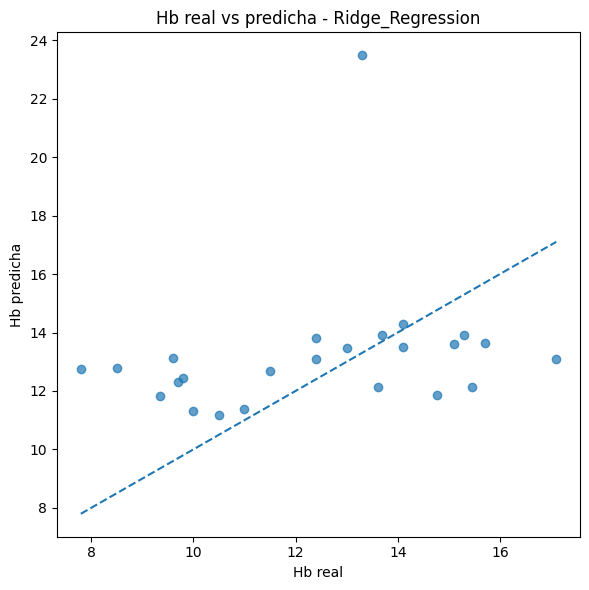

In [104]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

ridge_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=1e-8)),
    ("scaler", StandardScaler()),
    ("reg", Ridge(solver="lsqr", random_state=SEED))
])

ridge_params = {
    "reg__alpha": [0.1, 1, 10, 50, 100, 200, 500, 1000]
}

ridge_grid = GridSearchCV(
    ridge_model,
    ridge_params,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

ridge_grid.fit(X_train_reg, y_train_reg)

print("Mejores parámetros Ridge:", ridge_grid.best_params_)

ridge_best = ridge_grid.best_estimator_
pred = ridge_best.predict(X_test_reg)

res = evaluate_regressor("Ridge_Regression", y_test_reg, pred)
regression_results.append(res)

Mejores parámetros SVR: {'reg__C': 50, 'reg__epsilon': 0.2, 'reg__gamma': 0.001, 'reg__kernel': 'rbf'}

===== SVR =====
MAE: 1.745
RMSE: 2.2534
R2: 0.2057


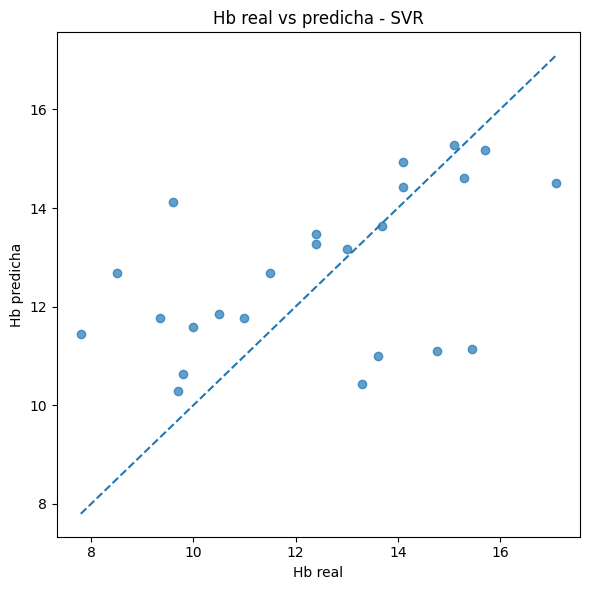

In [105]:
svr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("reg", SVR())
])

svr_params = {
    "reg__C": [0.1, 1, 10, 50, 100],
    "reg__gamma": ["scale", 0.01, 0.001],
    "reg__epsilon": [0.05, 0.1, 0.2, 0.3],
    "reg__kernel": ["rbf"]
}

svr_grid = GridSearchCV(
    svr_model,
    svr_params,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

svr_grid.fit(X_train_reg, y_train_reg)

print("Mejores parámetros SVR:", svr_grid.best_params_)

svr_best = svr_grid.best_estimator_
pred = svr_best.predict(X_test_reg)

res = evaluate_regressor("SVR", y_test_reg, pred)
regression_results.append(res)

In [107]:
def build_meta_array(df):
    rows = []

    for _, row in df.iterrows():
        age = to_float_safe(row["age"])

        if np.isnan(age):
            age = -1

        sex = encode_sex(row["sex"])
        country = 1 if row["country"] == "India" else 0

        rows.append([age, sex, country])

    return np.array(rows, dtype=np.float32)


class MobileNetRegressionSequence(tf.keras.utils.Sequence):
    def __init__(self, df, batch_size=16, img_size=(224, 224), shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.img_size = img_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, idx):
        batch_idx = self.indexes[idx*self.batch_size:(idx+1)*self.batch_size]
        batch = self.df.iloc[batch_idx]

        X_img = []
        X_meta = []
        y = []

        for _, row in batch.iterrows():
            img = load_preprocessed_image(row["image_path"], self.img_size)
            X_img.append(img.astype(np.float32))

            age = to_float_safe(row["age"])
            if np.isnan(age):
                age = -1

            sex = encode_sex(row["sex"])
            country = 1 if row["country"] == "India" else 0

            X_meta.append([age, sex, country])
            y.append(row["hb"])

        X_img = mobilenet_preprocess(np.array(X_img))
        X_meta = np.array(X_meta, dtype=np.float32)
        y = np.array(y, dtype=np.float32)

        return (X_img, X_meta), y


train_seq = MobileNetRegressionSequence(train_df_reg, batch_size=16, shuffle=True)
val_seq = MobileNetRegressionSequence(val_df_reg, batch_size=16, shuffle=False)
test_seq = MobileNetRegressionSequence(test_df_reg, batch_size=16, shuffle=False)

Epoch 1/40
7/7 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - loss: 9.5037 - mae: 9.5037 - val_loss: 7.4222 - val_mae: 7.4222 - learning_rate: 1.0000e-04
Epoch 2/40
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 613ms/step - loss: 7.1867 - mae: 7.1867 - val_loss: 5.4978 - val_mae: 5.4978 - learning_rate: 1.0000e-04
Epoch 3/40
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 600ms/step - loss: 5.1931 - mae: 5.1931 - val_loss: 3.4943 - val_mae: 3.4943 - learning_rate: 1.0000e-04
Epoch 4/40
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 602ms/step - loss: 4.3954 - mae: 4.3954 - val_loss: 2.4003 - val_mae: 2.4003 - learning_rate: 1.0000e-04
Epoch 5/40
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 549ms/step - loss: 3.8315 - mae: 3.8315 - val_loss: 2.1754 - val_mae: 2.1754 - learning_rate: 1.0000e-04
Epoch 6/40
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 596ms/step - loss: 3.2296 - mae: 3.2296 - val_loss: 2.1518 - val_mae: 2.1518 - learning_rate: 1.0000e-04
Epoch 7/40
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 483ms/step - loss: 3.2930 - mae: 3.2930 - val_loss: 2.1549 - val_mae: 2.1549 - learning_rate: 1.000

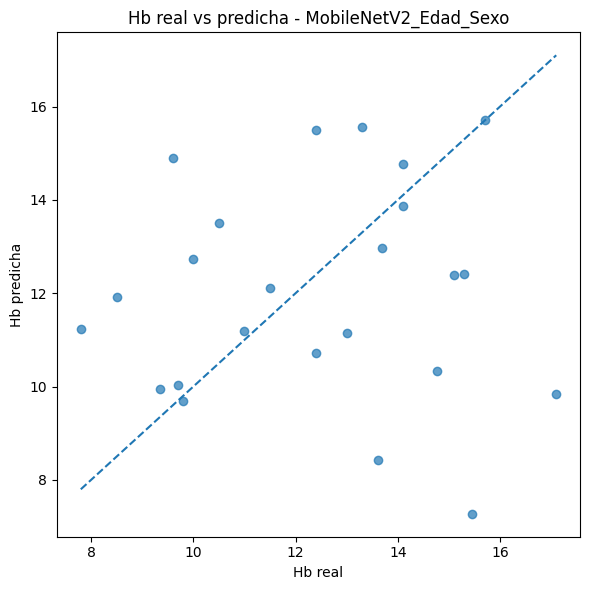

In [108]:
def build_mobilenet_age_sex_regressor():
    img_input = layers.Input(shape=(224, 224, 3), name="image_input")
    meta_input = layers.Input(shape=(3,), name="meta_input")

    base = MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_tensor=img_input
    )
    base.trainable = False

    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.35)(x)

    m = layers.Dense(16, activation="relu")(meta_input)

    z = layers.Concatenate()([x, m])
    z = layers.Dense(64, activation="relu")(z)
    z = layers.Dropout(0.25)(z)
    output = layers.Dense(1, activation="linear")(z)

    model = models.Model(inputs=[img_input, meta_input], outputs=output)
    return model

mobilenet_reg = build_mobilenet_age_sex_regressor()

mobilenet_reg.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="mae",
    metrics=["mae"]
)

mobilenet_reg.fit(
    train_seq,
    validation_data=val_seq,
    epochs=40,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=4),
        ModelCheckpoint(os.path.join(OUTPUT_DIR, "MobileNetV2_age_sex_regressor.keras"), save_best_only=True)
    ]
)

pred = mobilenet_reg.predict(test_seq).flatten()
y_test_mobile = test_df_reg["hb"].values

res = evaluate_regressor("MobileNetV2_Edad_Sexo", y_test_mobile, pred)
regression_results.append(res)

In [110]:
def build_slic_graph(image_path, img_size=(224, 224), n_segments=60):
    img_rgb = load_preprocessed_image(image_path, img_size)
    arr = img_rgb.astype(np.float32) / 255.0
    lab = rgb2lab(arr)

    segments = slic(arr, n_segments=n_segments, compactness=10, start_label=0)
    num_nodes = segments.max() + 1

    node_features = []

    for node_id in range(num_nodes):
        mask = segments == node_id

        rgb_vals = arr[mask]
        lab_vals = lab[mask]

        area = np.sum(mask) / (img_size[0] * img_size[1])

        ys, xs = np.where(mask)
        cx = np.mean(xs) / img_size[1]
        cy = np.mean(ys) / img_size[0]

        feats = []
        feats.extend(np.mean(rgb_vals, axis=0))
        feats.extend(np.std(rgb_vals, axis=0))
        feats.extend(np.mean(lab_vals, axis=0))
        feats.extend(np.std(lab_vals, axis=0))
        feats.extend([area, cx, cy])

        node_features.append(feats)

    node_features = np.array(node_features, dtype=np.float32)

    adj = np.eye(num_nodes, dtype=np.float32)

    right_diff = segments[:, 1:] != segments[:, :-1]
    a = segments[:, 1:][right_diff]
    b = segments[:, :-1][right_diff]
    adj[a, b] = 1
    adj[b, a] = 1

    down_diff = segments[1:, :] != segments[:-1, :]
    a = segments[1:, :][down_diff]
    b = segments[:-1, :][down_diff]
    adj[a, b] = 1
    adj[b, a] = 1

    return node_features, adj


class SLICGraphDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
        self.graphs = []

        for i, row in self.df.iterrows():
            if i % 25 == 0:
                print("Construyendo grafo", i, "de", len(self.df))

            x, adj = build_slic_graph(row["image_path"])
            y = float(row["hb"])
            self.graphs.append((x, adj, y))

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        x, adj, y = self.graphs[idx]

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(adj, dtype=torch.float32),
            torch.tensor([y], dtype=torch.float32)
        )

In [111]:
class SimpleGATLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()

        self.W = nn.Linear(in_features, out_features, bias=False)
        self.a_src = nn.Linear(out_features, 1, bias=False)
        self.a_dst = nn.Linear(out_features, 1, bias=False)
        self.leaky_relu = nn.LeakyReLU(0.2)

    def forward(self, x, adj):
        h = self.W(x)

        src = self.a_src(h)
        dst = self.a_dst(h)

        e = self.leaky_relu(src + dst.T)
        e = e.masked_fill(adj == 0, -1e9)

        alpha = torch.softmax(e, dim=1)
        out = alpha @ h

        return torch.relu(out)


class SLICGATRegressor(nn.Module):
    def __init__(self, in_features):
        super().__init__()

        self.gat1 = SimpleGATLayer(in_features, 32)
        self.gat2 = SimpleGATLayer(32, 32)

        self.regressor = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 1)
        )

    def forward(self, x, adj):
        h = self.gat1(x, adj)
        h = self.gat2(h, adj)

        graph_emb = torch.mean(h, dim=0)
        out = self.regressor(graph_emb)

        return out

In [112]:
train_graph_ds = SLICGraphDataset(train_df_reg)
val_graph_ds = SLICGraphDataset(val_df_reg)
test_graph_ds = SLICGraphDataset(test_df_reg)

in_features = train_graph_ds[0][0].shape[1]

slic_gat = SLICGATRegressor(in_features=in_features).to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.AdamW(slic_gat.parameters(), lr=1e-3, weight_decay=1e-4)

best_val = np.inf
best_state = None
patience = 10
wait = 0

for epoch in range(80):
    slic_gat.train()
    train_loss = 0

    for x, adj, y in train_graph_ds:
        x = x.to(device)
        adj = adj.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        pred = slic_gat(x, adj)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    slic_gat.eval()
    val_loss = 0

    with torch.no_grad():
        for x, adj, y in val_graph_ds:
            x = x.to(device)
            adj = adj.to(device)
            y = y.to(device)

            pred = slic_gat(x, adj)
            loss = criterion(pred, y)

            val_loss += loss.item()

    print(f"Epoch {epoch+1} | Train MAE: {train_loss/len(train_graph_ds):.4f} | Val MAE: {val_loss/len(val_graph_ds):.4f}")

    if val_loss < best_val:
        best_val = val_loss
        best_state = slic_gat.state_dict()
        wait = 0
    else:
        wait += 1

        if wait >= patience:
            print("Early stopping")
            break

slic_gat.load_state_dict(best_state)

Construyendo grafo 0 de 107
Construyendo grafo 25 de 107
Construyendo grafo 50 de 107
Construyendo grafo 75 de 107
Construyendo grafo 100 de 107
Construyendo grafo 0 de 23
Construyendo grafo 0 de 24
Epoch 1 | Train MAE: 7.8868 | Val MAE: 4.8995
Epoch 2 | Train MAE: 3.9087 | Val MAE: 2.5513
Epoch 3 | Train MAE: 3.2157 | Val MAE: 3.6161
Epoch 4 | Train MAE: 2.8447 | Val MAE: 3.1881
Epoch 5 | Train MAE: 3.0914 | Val MAE: 3.1363
Epoch 6 | Train MAE: 2.7974 | Val MAE: 2.2302
Epoch 7 | Train MAE: 2.6537 | Val MAE: 2.4946
Epoch 8 | Train MAE: 2.6648 | Val MAE: 2.2804
Epoch 9 | Train MAE: 2.5202 | Val MAE: 2.2701
Epoch 10 | Train MAE: 2.5891 | Val MAE: 2.9130
Epoch 11 | Train MAE: 2.2640 | Val MAE: 2.2404
Epoch 12 | Train MAE: 2.4991 | Val MAE: 2.3694
Epoch 13 | Train MAE: 2.5620 | Val MAE: 3.2920
Epoch 14 | Train MAE: 2.5141 | Val MAE: 2.1861
Epoch 15 | Train MAE: 2.4313 | Val MAE: 2.1944
Epoch 16 | Train MAE: 2.6190 | Val MAE: 2.2018
Epoch 17 | Train MAE: 2.4122 | Val MAE: 2.5514
Epoch 18 | 

<All keys matched successfully>


===== SLIC_GAT =====
MAE: 2.6053
RMSE: 3.0799
R2: -0.4839


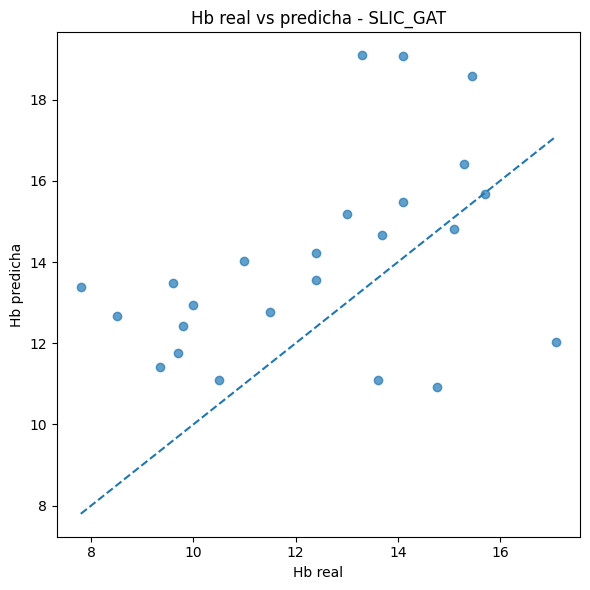

In [113]:
slic_gat.eval()
preds = []
trues = []

with torch.no_grad():
    for x, adj, y in test_graph_ds:
        x = x.to(device)
        adj = adj.to(device)

        pred = slic_gat(x, adj).cpu().numpy()[0]

        preds.append(pred)
        trues.append(y.numpy()[0])

preds = np.array(preds)
trues = np.array(trues)

res = evaluate_regressor("SLIC_GAT", trues, preds)
regression_results.append(res)

In [114]:
class ImageRegressionDataset(Dataset):
    def __init__(self, df, img_size=224):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
        self.std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img = load_preprocessed_image(row["image_path"], (self.img_size, self.img_size))
        arr = img.astype(np.float32) / 255.0
        arr = np.transpose(arr, (2, 0, 1))
        arr = (arr - self.mean) / self.std

        y = np.array([row["hb"]], dtype=np.float32)

        return torch.tensor(arr, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)


train_reg_torch = ImageRegressionDataset(train_df_reg)
val_reg_torch = ImageRegressionDataset(val_df_reg)
test_reg_torch = ImageRegressionDataset(test_df_reg)

train_reg_loader = DataLoader(train_reg_torch, batch_size=8, shuffle=True)
val_reg_loader = DataLoader(val_reg_torch, batch_size=8, shuffle=False)
test_reg_loader = DataLoader(test_reg_torch, batch_size=8, shuffle=False)

In [115]:
import copy

def train_deit_regressor(model_name="deit_small_patch16_224", epochs=60, lr=2e-5):
    model = timm.create_model(model_name, pretrained=True, num_classes=1)
    model = model.to(device)

    criterion = nn.L1Loss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)

    best_val = np.inf
    best_state = None
    patience = 10
    wait = 0

    for epoch in range(epochs):
        model.train()
        train_loss = 0

        for images, y in train_reg_loader:
            images = images.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            pred = model(images)
            loss = criterion(pred, y)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

            train_loss += loss.item()

        model.eval()
        val_loss = 0

        with torch.no_grad():
            for images, y in val_reg_loader:
                images = images.to(device)
                y = y.to(device)

                pred = model(images)
                loss = criterion(pred, y)

                val_loss += loss.item()

        train_mae = train_loss / len(train_reg_loader)
        val_mae = val_loss / len(val_reg_loader)

        print(f"Epoch {epoch+1} | Train MAE: {train_mae:.4f} | Val MAE: {val_mae:.4f}")

        if val_mae < best_val:
            best_val = val_mae
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1

            if wait >= patience:
                print("Early stopping")
                break

    model.load_state_dict(best_state)
    print("Mejor Val MAE:", round(best_val, 4))

    return model


deit_reg = train_deit_regressor(
    model_name="deit_small_patch16_224",
    epochs=60,
    lr=2e-5
)

Epoch 1 | Train MAE: 10.4523 | Val MAE: 6.4881
Epoch 2 | Train MAE: 5.8236 | Val MAE: 3.9841
Epoch 3 | Train MAE: 4.2014 | Val MAE: 3.2393
Epoch 4 | Train MAE: 3.5503 | Val MAE: 3.0096
Epoch 5 | Train MAE: 3.4438 | Val MAE: 2.8761
Epoch 6 | Train MAE: 3.3289 | Val MAE: 2.7899
Epoch 7 | Train MAE: 3.1768 | Val MAE: 2.7315
Epoch 8 | Train MAE: 3.1236 | Val MAE: 2.6649
Epoch 9 | Train MAE: 3.0037 | Val MAE: 2.6027
Epoch 10 | Train MAE: 2.9247 | Val MAE: 2.5462
Epoch 11 | Train MAE: 2.9100 | Val MAE: 2.4855
Epoch 12 | Train MAE: 2.7384 | Val MAE: 2.4545
Epoch 13 | Train MAE: 2.6639 | Val MAE: 2.4054
Epoch 14 | Train MAE: 2.5713 | Val MAE: 2.3612
Epoch 15 | Train MAE: 2.4345 | Val MAE: 2.3187
Epoch 16 | Train MAE: 2.5134 | Val MAE: 2.2546
Epoch 17 | Train MAE: 2.4184 | Val MAE: 2.2063
Epoch 18 | Train MAE: 2.3278 | Val MAE: 2.1673
Epoch 19 | Train MAE: 2.2364 | Val MAE: 2.1791
Epoch 20 | Train MAE: 2.1132 | Val MAE: 2.2093
Epoch 21 | Train MAE: 2.0174 | Val MAE: 2.1525
Epoch 22 | Train MAE:


===== DeiT_ViT_Regressor =====
MAE: 1.6647
RMSE: 2.1697
R2: 0.2636


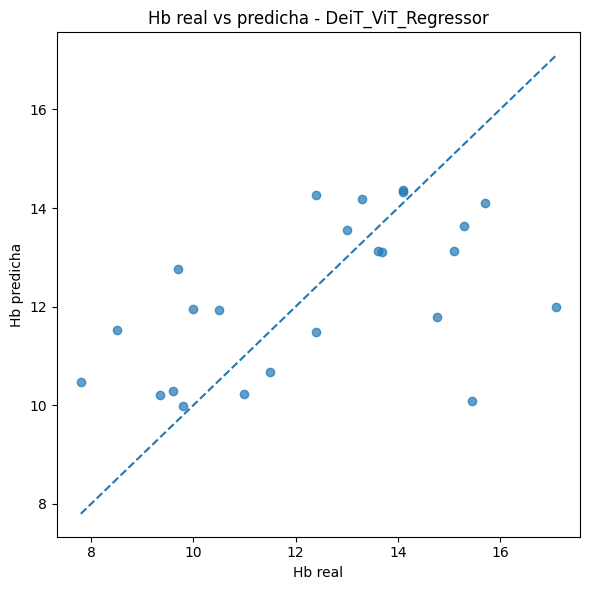

In [116]:
deit_reg.eval()
preds = []
trues = []

with torch.no_grad():
    for images, y in test_reg_loader:
        images = images.to(device)
        pred = deit_reg(images).cpu().numpy().flatten()

        preds.extend(pred)
        trues.extend(y.numpy().flatten())

preds = np.array(preds)
trues = np.array(trues)

res = evaluate_regressor("DeiT_ViT_Regressor", trues, preds)
regression_results.append(res)

In [117]:
classification_df = pd.DataFrame(classification_results)
classification_df = classification_df.sort_values(
    by=["AUC", "F1-score", "Accuracy"],
    ascending=False
)

regression_df = pd.DataFrame(regression_results)
regression_df = regression_df.sort_values(
    by=["MAE", "RMSE"],
    ascending=True
)

display(classification_df.round(4))
display(regression_df.round(4))

,Modelo,Threshold,Accuracy,Precision,Sensibilidad,Especificidad,F1-score,AUC,TP,FN,FP,TN
0,kNN_SMOTE_ROSE,0.40,0.8131,0.8143,0.8906,0.6977,0.8507,0.9182,57,7,13,30
3,MobileNetV2_SVM,0.43,0.7383,0.7571,0.8281,0.6047,0.7910,0.8692,53,11,17,26
4,DeiT_ViT,0.17,0.7290,0.7536,0.8125,0.6047,0.7820,0.8656,52,12,17,26
1,RUSBoost,0.05,0.5981,0.5981,1.0000,0.0000,0.7485,0.5823,64,0,43,0
2,CNN,0.05,0.5981,0.5981,1.0000,0.0000,0.7485,0.5080,64,0,43,0


,Modelo,MAE,RMSE,R2
4,DeiT_ViT_Regressor,1.6647,2.1697,0.2636
1,SVR,1.7450,2.2534,0.2057
0,Ridge_Regression,2.2702,3.1093,-0.5123
2,MobileNetV2_Edad_Sexo,2.5379,3.3714,-0.7780
3,SLIC_GAT,2.6053,3.0799,-0.4839


In [118]:
excel_path = os.path.join(OUTPUT_DIR, "resultados_solo_modelos_matriz.xlsx")

with pd.ExcelWriter(excel_path) as writer:
    classification_df.to_excel(writer, sheet_name="Clasificacion", index=False)
    regression_df.to_excel(writer, sheet_name="Regresion_Hb", index=False)

print("Excel guardado en:", excel_path)

Excel guardado en: /kaggle/working/resultados_modelos_solo_matriz/resultados_solo_modelos_matriz.xlsx


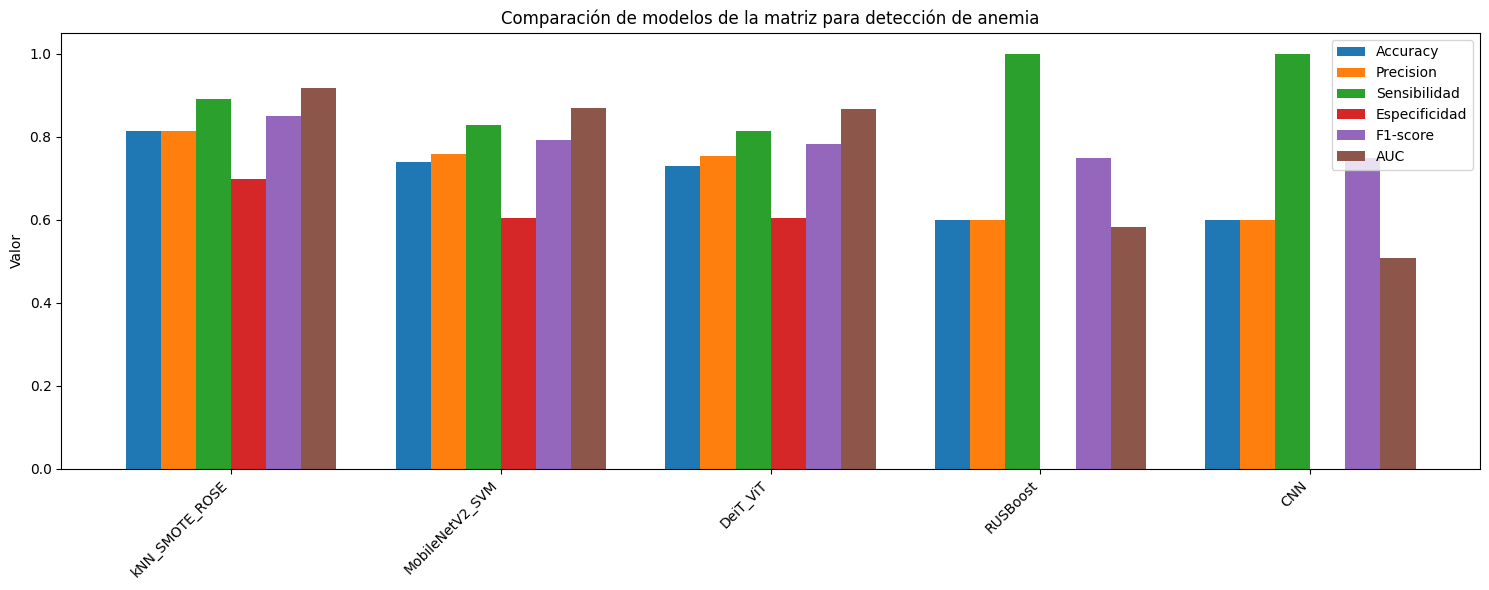

Guardado: /kaggle/working/resultados_modelos_solo_matriz/grafico_clasificacion_solo_matriz.png


In [119]:
metrics_to_plot = ["Accuracy", "Precision", "Sensibilidad", "Especificidad", "F1-score", "AUC"]

plot_df = classification_df.copy()

plt.figure(figsize=(15, 6))
x = np.arange(len(plot_df["Modelo"]))
width = 0.13

for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + i * width, plot_df[metric], width, label=metric)

plt.xticks(x + width * 2.5, plot_df["Modelo"], rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.ylabel("Valor")
plt.title("Comparación de modelos de la matriz para detección de anemia")
plt.legend()
plt.tight_layout()

path_cls = os.path.join(OUTPUT_DIR, "grafico_clasificacion_solo_matriz.png")
plt.savefig(path_cls, dpi=300, bbox_inches="tight")
plt.show()

print("Guardado:", path_cls)

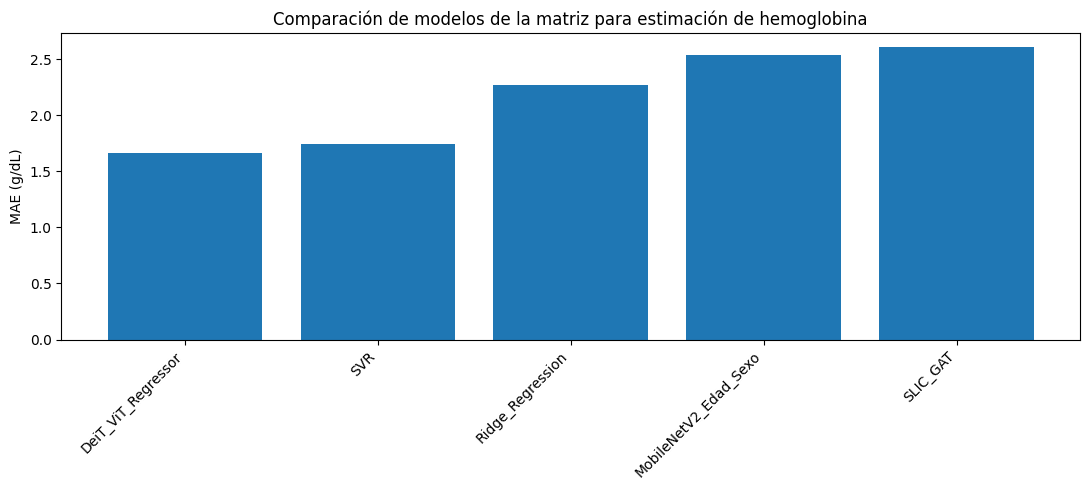

Guardado: /kaggle/working/resultados_modelos_solo_matriz/grafico_regresion_solo_matriz.png


In [120]:
plt.figure(figsize=(11, 5))
plt.bar(regression_df["Modelo"], regression_df["MAE"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("MAE (g/dL)")
plt.title("Comparación de modelos de la matriz para estimación de hemoglobina")
plt.tight_layout()

path_reg = os.path.join(OUTPUT_DIR, "grafico_regresion_solo_matriz.png")
plt.savefig(path_reg, dpi=300, bbox_inches="tight")
plt.show()

print("Guardado:", path_reg)

In [122]:
print("MEJOR MODELO DE CLASIFICACIÓN")
print("--------------------------------")
best_cls = classification_df.sort_values(
    by=["AUC", "F1-score", "Accuracy"],
    ascending=False
).iloc[0]
print(best_cls)

print("\nMEJOR MODELO DE REGRESIÓN")
print("--------------------------------")
best_reg = regression_df.sort_values(
    by=["MAE", "RMSE"],
    ascending=True
).iloc[0]
print(best_reg)

MEJOR MODELO DE CLASIFICACIÓN
--------------------------------
Modelo           kNN_SMOTE_ROSE
Threshold                   0.4
Accuracy               0.813084
Precision              0.814286
Sensibilidad           0.890625
Especificidad          0.697674
F1-score               0.850746
AUC                    0.918241
TP                           57
FN                            7
FP                           13
TN                           30
Name: 0, dtype: object

MEJOR MODELO DE REGRESIÓN
--------------------------------
Modelo    DeiT_ViT_Regressor
MAE                 1.664718
RMSE                2.169734
R2                  0.263594
Name: 4, dtype: object


In [123]:
import os
import shutil

RESULTS_DIR = "/kaggle/working/resultados_modelos_solo_matriz"
ZIP_PATH = "/kaggle/working/resultados_modelos_solo_matriz"

print("Existe carpeta de resultados:", os.path.exists(RESULTS_DIR))

if os.path.exists(RESULTS_DIR):
    print("Archivos encontrados:")
    print(os.listdir(RESULTS_DIR))

    shutil.make_archive(ZIP_PATH, "zip", RESULTS_DIR)
    print("ZIP creado en:", ZIP_PATH + ".zip")
else:
    print("No existe la carpeta de resultados.")

Existe carpeta de resultados: True
Archivos encontrados:
['matriz_confusion_RUSBoost.png', 'real_vs_pred_Ridge_Regression.png', 'resultados_solo_modelos_matriz.xlsx', 'grafico_clasificacion_solo_matriz.png', 'matriz_confusion_kNN_SMOTE_ROSE.png', 'real_vs_pred_SLIC_GAT.png', 'MobileNetV2_age_sex_regressor.keras', 'matriz_confusion_DeiT_ViT.png', 'matriz_confusion_MobileNetV2_SVM.png', 'real_vs_pred_MobileNetV2_Edad_Sexo.png', 'real_vs_pred_DeiT_ViT_Regressor.png', 'matriz_confusion_CNN.png', 'CNN_model.keras', 'real_vs_pred_SVR.png', 'grafico_regresion_solo_matriz.png']
ZIP creado en: /kaggle/working/resultados_modelos_solo_matriz.zip
